In [ ]:
import networkx as nx
from IPython.display import SVG, display
import os
import tempfile

nodes = {

    "Mission": ["mission",],
    "Context": ["leadership_vision","leadership_objectives","stakeholder_demands","stakeholder_questions","problem_statement",],
    "Problem Definition": ["stakeholders","related_agents","questions","requirements","timeline",],
    "Agent Properties": ["aor","assets","objectives","tasking",], # leave-unstaged
    "Assessment": ["overall_assessment","criteria_and_weighting","input_data", "logic","analysis","modeling_and_sim","outputs","recommendations",],
}

stage_style = {
    "Mission": {"fillcolor": "dodgerblue2","shape": "pentagon",},
    "Context": {"fillcolor": "lightblue","shape": "box",},
    "Problem Definition": {"fillcolor": "lightgreen","shape": "box",},
    "Agent Properties": {"fillcolor": "khaki","shape": "box",},
    "Assessment": {"fillcolor": "lightcoral","shape": "box",},
}

categories = {

    "Drivers": ["mission","leadership_vision","leadership_objectives","stakeholder_demands","stakeholder_questions","problem_statement",],
    "Demands": ["stakeholders","related_agents","questions","requirements","timeline",],
    "Agent_Attributes": ["aor","assets","objectives","tasking",],
    "Assessment": ["overall_assessment","criteria_and_weighting","input_data","logic","analysis","modeling_and_sim",],
    "Deliverables": ["outputs","recommendations",],
}

G = nx.DiGraph()
for stage, items in nodes.items():
    for item in items:
        category = [c for c, vals in categories.items()if item in vals][0]
        G.add_node(item,stage=stage,category=category,**stage_style[stage])

relations = {
    "context_flow": list(zip(categories['Drivers'][1:], categories['Drivers'][2:])),
    #"problem_definition": [("problem_statement", "stakeholders"),("problem_statement", "related_agents"),("problem_statement", "questions"),("problem_statement", "requirements"),("problem_statement", "timeline"),],
    #"agent_properties": [(agent, prop) for agent in ["stakeholders","related_agents",] for prop in nodes["Agent Properties"]],
    "problem_to_assessment": [(item, "overall_assessment")for item in nodes["Problem Definition"]],
    #"context_to_assessment": [(item, "overall_assessment")for item in nodes["Context"]],
    "assessment_structure": [("overall_assessment", item) for item in nodes["Assessment"] if item not in ["overall_assessment", "recommendations", "outputs"]],
    "assessment_outputs": [(item, "outputs") for item in ["criteria_and_weighting","input_data","logic","analysis","modeling_and_sim",]],
    "recommendations": [("outputs", "recommendations")],
}

for relation, edge_list in relations.items():
    for u, v in edge_list:
        G.add_edge(u,v,relation=relation)




In [2]:
# -----------------------------
# Graph Formatting
# -----------------------------

A.graph_attr.update({
    "rankdir": "TB",
    "ranksep": "1.0",
    "nodesep": "0.8",
    "splines": "polyline",
    "compound": "true",
})

A.node_attr.update({
    "style": "rounded,filled",
    "fontname": "Helvetica-Bold",
    "fontsize": "12",
    "penwidth": "2",
    "margin": "0.25,0.15",
})

A.edge_attr.update({
    "fontname": "Helvetica-Bold",
    "fontsize": "10",
    "penwidth": "1.5",
    "arrowsize": "0.3",
})


# -----------------------------
# Create cluster anchors
# -----------------------------

anchors = {}

for stage, items in nodes.items():

    if stage == "Mission":
        continue

    anchor = f"{stage.replace(' ', '_')}_anchor"
    anchors[stage] = anchor

    # Invisible cluster handle
    A.add_node(
        anchor,
        label="",
        shape="point",
        width="0.01",
        height="0.01",
        style="invis",
    )

    cluster = A.add_subgraph(
        items + [anchor],
        name=f"cluster_{stage.replace(' ', '_')}",
        label=stage,
    )

    cluster.graph_attr.update({
        "style": "rounded",
        "color": "gray70",
        "margin": "20",
    })


# -----------------------------
# Internal cluster ordering
# -----------------------------

# Context: left-to-right flow
for u, v in relations["context_flow"]:
    edge = A.get_edge(u, v)
    edge.attr["constraint"] = "false"


# Problem Definition: vertical stack
for u, v in zip(
    nodes["Problem Definition"][:-1],
    nodes["Problem Definition"][1:]
):
    A.add_edge(
        u,
        v,
        style="invis",
        weight="50",
    )


# Agent Properties: vertical stack
for u, v in zip(
    nodes["Agent Properties"][:-1],
    nodes["Agent Properties"][1:]
):
    A.add_edge(
        u,
        v,
        style="invis",
        weight="50",
    )


# Assessment layout remains controlled by real edges


# -----------------------------
# Cluster alignment
# -----------------------------

# Put breakout clusters on the same horizontal level
with A.add_subgraph(name="main_alignment") as s:
    s.graph_attr["rank"] = "same"
    s.add_nodes_from([
        anchors["Agent Properties"],
        anchors["Problem Definition"],
        anchors["Assessment"],
    ])


# Left-to-right ordering
A.add_edge(
    anchors["Agent Properties"],
    anchors["Problem Definition"],
    style="invis",
    weight="500",
)

A.add_edge(
    anchors["Problem Definition"],
    anchors["Assessment"],
    style="invis",
    weight="500",
)


# -----------------------------
# Context / Mission placement
# -----------------------------

# Mission above Context
A.add_edge(
    "mission",
    anchors["Context"],
    weight="200",
)


# Place Context above the main working row
A.add_edge(
    anchors["Context"],
    anchors["Problem Definition"],
    style="invis",
    weight="100",
)


# -----------------------------
# Attach breakout relationships
# -----------------------------

# Use actual nodes instead of anchors
# This avoids rank conflicts

A.add_edge(
    "stakeholders",
    "aor",
    style="invis",
    weight="50",
)

A.add_edge(
    "related_agents",
    "aor",
    style="invis",
    weight="50",
)


# -----------------------------
# Remove dense many-to-one edges
# -----------------------------

for node in nodes["Problem Definition"]:
    if A.has_edge(node, "overall_assessment"):
        A.remove_edge(node, "overall_assessment")


# -----------------------------
# Feedback loop
# -----------------------------

A.add_edge(
    "recommendations",
    "problem_statement",
    style="dashed",
    constraint="false",
)

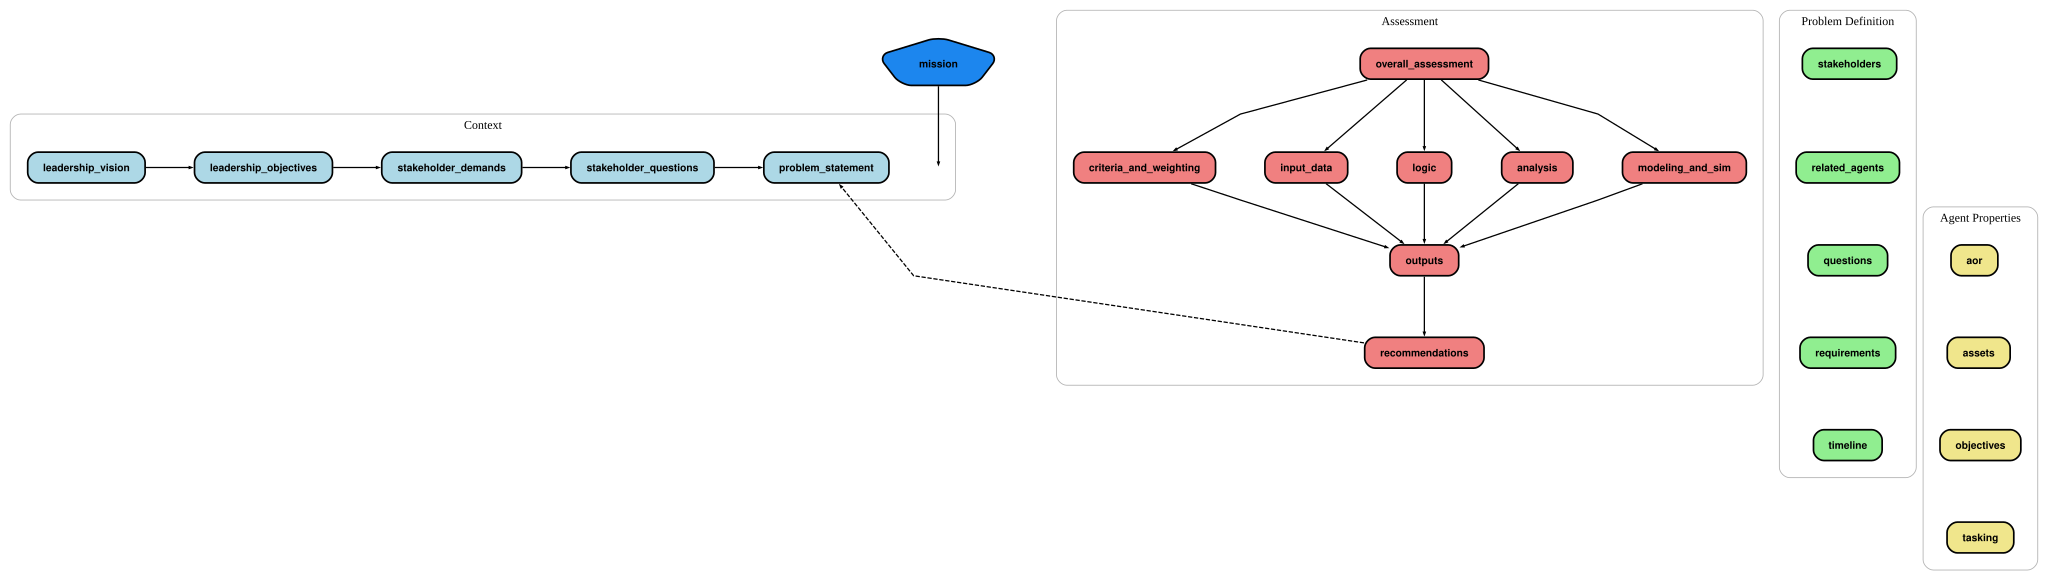

In [4]:
from IPython.display import SVG, display

with tempfile.NamedTemporaryFile(
    suffix=".svg",
    delete=False
) as f:
    filename = f.name

try:
    A.draw(
        filename,
        format="svg",
        prog="dot"
    )

    with open(filename, "r") as svg_file:
        svg_content = svg_file.read()

    display(SVG(svg_content))

finally:
    os.remove(filename)